
# Three-level QCQP cascade: scattering, total field, current

Bound on the scattered power $\tfrac12 I^H R_0 I$ of a structure carved out of the copper 2:1 plate (`*_patch21ka1.txt`, $ka = 1$ at 2.45 GHz,
plane wave $E_0 = 1$ kV/m), in the RWG basis with $Z_\mathrm{mat} = Z_s L$ and the scattered voltage $x = V_\mathrm{sca} = -Z_0 I$ as the
variable. The dual current of the scattering bound is degenerate (hard case), so it is made unique lexicographically. Each level is a quadratically
constrained quadratic program refined by GCD; there is no reweighting and no linearization. The next level works in the near-kernel of the
previous level's Lagrangian:

1. **Scattering**: maximize $\tfrac12 I^H R_0 I$, global bound and GCD (full space).
2. **Total field**: in the near-kernel $N$ of the GCD Lagrangian ($\epsilon = 10^{-4}$, about 0.5 % of the Lagrangian), minimize $\sum_i |V_i + x_i|^2$:
   a fresh global bound (power constraints $p = \mathbf 1, j\mathbf 1$), then GCD.
3. **Current**: in the near-kernel of the level-2 Lagrangian (eigenvalues below $10^{-3}$ of the largest), minimize $\sum_i |I_i|^2$: again a fresh
   global bound in the new kernel, then GCD.

Every level starts from the global power constraints only; the GCD constraints of a level are not inherited. A level's own GCD therefore has
room even in a small kernel, while the fixed parts of the previous levels carry their information.

**Constraints and GCD.** All constraints are projector constraints of the library form, $\operatorname{Re}\sum_i \overline{p_i}\, w_i = 0$ with the local complex
power $w_i = \overline{I_i}(V - Z_\mathrm{tot} I)_i$, mapped into each kernel by `projectorForm`/`shiftForm`. GCD adds the max-violation projector $p = w$,
which carries the real and the reactive local power, and the min-eigenvalue projector.

**Objectives.** The objectives of levels 2 and 3 are positive definite, so $\lambda = 0$ is dual feasible and each level's dual is a lower bound on its
objective among currents that keep the fixed parts of the previous levels.

**Inference.** The final current of each level is used for pointwise inference: binary and relaxed designs, and the complex material density.


In [1]:
import contextlib
import copy
import io
import time

import matplotlib.pyplot as plt
import numpy as np
import scipy.io as sio
import scipy.linalg as la
import scipy.sparse as sp
from matplotlib.collections import LineCollection, PolyCollection
from matplotlib.colors import LogNorm
from scipy.optimize import least_squares

from dolphindes.cvxopt import DenseSharedProjQCQP, OptimizationHyperparameters
from dolphindes.cvxopt.gcd import GCDHyperparameters

In [2]:
matrixSet = "patch21ka1" # copper 2:1 plate, ka = 1; omW and the mesh exist for this set only (exportOmWpatch21ka1.m)

# Physical constants
epsilon_0 = 8.854e-12 # F/m
mu_0 = 4e-7 * np.pi # H/m
c = 1/np.sqrt(epsilon_0 * mu_0) # speed of light in vacuum
eta_0 = np.sqrt(mu_0/epsilon_0) # free-space impedance

E0 = 1e3 # plane wave amplitude in V/m

frequency = 2.45e9 # frequency in Hz
omega = 2 * np.pi * frequency # angular frequency

copper_conductivity = 5.96e7 # S/m
delta = np.sqrt(2 / (omega * mu_0 * copper_conductivity)) # skin depth in m
Zs = (1 + 1j) / (copper_conductivity * delta) # surface impedance
print(f"Surface impedance: {Zs} Ω")

Surface impedance: (0.012739130327240646+0.012739130327240646j) Ω


In [3]:
def Msym(M):
    return(0.5*(M.conj().T + M))

# Load matrices from text files (original RWG basis, no Cholesky transformation)
Lmat = np.loadtxt(f"Lmat_{matrixSet}.txt", delimiter=',') # lossy matrix
R0 = Msym(np.loadtxt(f"R0_{matrixSet}.txt", delimiter=',')) # radiated power matrix
X0 = Msym(np.loadtxt(f"X0_{matrixSet}.txt", delimiter=',')) # reactive power matrix
Vinc = E0*np.loadtxt(f"V_{matrixSet}.txt", delimiter=',').astype(complex) # voltage excitation vector

Ndes = Lmat.shape[0] # number of design variables
print(f"Matrix set: {matrixSet}, number of design variables: {Ndes}")

Zmat = Zs * Lmat # material impedance matrix (non-diagonal)
Z0 = R0 + 1j*X0 # free-space impedance matrix
Ztot = Z0 + Zmat # total impedance matrix
Ldiag = np.diag(Lmat).copy() # diagonal of the lossy matrix

def evalObj(Ivec):
    # scattered (radiated) power
    return(0.5*np.real(Ivec.conj() @ R0 @ Ivec))

# full plate performance
Ifull = np.linalg.solve(Ztot, Vinc)
Pfull = evalObj(Ifull)
print(f"Objective for full plate: {Pfull:.6e} W")

# reference: lossless resonant electric dipole, sigma_sca = 3 lambda^2 / (2 pi)
Pdip = 3*(c/frequency)**2/(2*np.pi) * E0**2/(2*eta_0)
print(f"resonant dipole scattered power: {Pdip:.4f} W")

Matrix set: patch21ka1, number of design variables: 233
Objective for full plate: 4.114174e-02 W
resonant dipole scattered power: 9.4884 W


In [4]:
# mesh of the operators (exportOmWpatch21ka1.m): bf[n] = [T+, T-, edge node 1, edge node 2], 0 based
mesh = sio.loadmat(f"mesh_{matrixSet}.mat")
nodes, tria, bf = mesh["nodes"], mesh["triangles"], mesh["bf"]
edgeLen = np.linalg.norm(nodes[bf[:, 2]] - nodes[bf[:, 3]], axis=1)
e1, e2 = nodes[tria[:, 1]] - nodes[tria[:, 0]], nodes[tria[:, 2]] - nodes[tria[:, 0]]
triArea = 0.5*np.abs(e1[:, 0]*e2[:, 1] - e1[:, 1]*e2[:, 0])
triCent = nodes[tria].mean(axis=1)
freeNode = np.array([[np.setdiff1d(tria[t], bf[n, 2:])[0] for t in bf[n, :2]] for n in range(Ndes)]) # free vertices of T+, T-
print(f"{len(nodes)} nodes, {len(tria)} triangles, plate {np.ptp(nodes[:, 0])*1e3:.2f} x {np.ptp(nodes[:, 1])*1e3:.2f} mm, "
      f"Lmat_nn = 0.481 l_n^2 (equilateral RWG): max rel. error {np.max(np.abs(Ldiag/(5/(6*np.sqrt(3))*edgeLen**2) - 1)):.1e}")

def currentDensity(I):
    # RWG current density at the triangle centroids, J = I_n l_n rho / (2 A)
    J = np.zeros((len(tria), 2), dtype=complex)
    for s, sgn in [(0, 1), (1, -1)]:
        rho = sgn*(triCent[bf[:, s]] - nodes[freeNode[:, s]])
        np.add.at(J, bf[:, s], (I*edgeLen/(2*triArea[bf[:, s]]))[:, None]*rho)
    return J

def plotStructure(ax, keep, I, title=""):
    # metal triangles colored by |J| (log); removed RWG functions between metal triangles are slots (red), void triangles white
    metal = np.zeros(len(tria), dtype=bool)
    metal[bf[keep, :2].ravel()] = True
    J = np.linalg.norm(np.abs(currentDensity(I)), axis=1)
    pc = PolyCollection(nodes[tria[metal]], array=np.maximum(J[metal], 1e-3*J.max()), cmap='viridis',
                        norm=LogNorm(1e-3*J.max(), J.max()), edgecolors='none')
    ax.add_collection(pc)
    ax.add_collection(PolyCollection(nodes[tria[~metal]], facecolors='white', edgecolors='0.85', linewidths=0.3))
    slot = ~keep & metal[bf[:, 0]] & metal[bf[:, 1]]
    ax.add_collection(LineCollection(nodes[bf[slot, 2:]], colors='r', linewidths=1.5))
    ax.set_xlim(nodes[:, 0].min(), nodes[:, 0].max()); ax.set_ylim(nodes[:, 1].min(), nodes[:, 1].max())
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=9)
    return pc

def plotDensity(ax, d, title=""):
    # inferred density on the RWG edges
    lc = LineCollection(nodes[bf[:, 2:]], array=np.log10(np.maximum(d, 1e-6)), cmap='viridis', linewidths=2.5)
    lc.set_clim(-6, 0)
    ax.add_collection(lc)
    ax.set_xlim(nodes[:, 0].min(), nodes[:, 0].max()); ax.set_ylim(nodes[:, 1].min(), nodes[:, 1].max())
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=9)
    return lc

def plotComplexDensity(axes, d, title=""):
    # complex density on the RWG edges: Re d (1 metal, 0 void) and Im d (0 for any structure), on a common symmetric scale
    dmax = np.quantile(np.abs(d), 0.99)
    for ax, part, name in [(axes[0], d.real, "Re d"), (axes[1], d.imag, "Im d")]:
        lc = LineCollection(nodes[bf[:, 2:]], array=part, cmap='RdBu_r', linewidths=2.5)
        lc.set_clim(-dmax, dmax)
        ax.add_collection(lc)
        ax.set_xlim(nodes[:, 0].min(), nodes[:, 0].max()); ax.set_ylim(nodes[:, 1].min(), nodes[:, 1].max())
        ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{title}: {name}, scale \u00b1{dmax:.1e}", fontsize=8)
        plt.colorbar(lc, ax=ax, shrink=0.8, format='%.0e')
    return lc

104 nodes, 168 triangles, plate 35.05 x 17.00 mm, Lmat_nn = 0.481 l_n^2 (equilateral RWG): max rel. error 2.6e-14


## Scattering QCQP, global and GCD bounds

As in `maxScatFixQ.ipynb`: $A_0 = -\tfrac12 W^H R_0 W$ with $W = Z_0^{-1}$, $I = -W x$, and the projector constraints
$\operatorname{Re}(-x^H A_1 P A_2 x + 2 x^H A_2^H P^H s_1) = 0$ with $A_1 = 1 + W^H Z_\mathrm{mat}^H$, $A_2 = W$, $s_1 = -\tfrac12 V$, i.e.
$\operatorname{Re}\sum_i p_i^* w_i = 0$, $w_i = I_i^*(V - Z_\mathrm{tot} I)_i$. The global bound uses $p = \mathbf 1$ and $p = j\mathbf 1$; GCD adds
two diagonal projectors per iteration (20 iterations, no merging). GCD is slightly non-deterministic (ARPACK starts and the random
`Pstruct` coefficients).

In [5]:
print(f"cond(Z0) = {np.linalg.cond(Z0):.3e}")
W = np.linalg.inv(Z0) # Z0^{-1}
WH = W.conj().T

Obj = -0.5 * Msym(WH @ R0 @ W)
obj = np.zeros(Ndes, dtype=complex)
obj0 = 0.0
A1 = np.eye(Ndes) + WH @ Zmat.conj().T
A2 = W
s1 = -0.5 * Vinc

def VtoI(Vsca):
    return(-W @ Vsca)

def localViolation(I):
    # pointwise w_i = I_i^* (V - Ztot I)_i, zero for any structure made of enabled basis functions
    return(np.conj(I)*(Vinc - Ztot @ I))

def constraintRes(Q, x):
    # c_k(x) = Re(-x^H A_k x + 2 x^H F_k) + c_k for all constraints (W), zero for a feasible x
    res = np.real(-x.conj() @ Q._allA_at_v(x) + 2*x.conj() @ Q.Fs)
    res[Q.n_proj_constr:] += Q.c_2j
    return res

def lagSpectrum(Q):
    return np.linalg.eigvalsh(Msym(Q._get_total_A(Q.current_lags)))

opt_params = OptimizationHyperparameters(opttol=1e-8,
    gradConverge=True,
    min_inner_iter=10,
    max_restart=20,
    penalty_ratio=1e-2,
    penalty_reduction=0.1,
    break_iter_period=5,
    verbose=0)

np.random.seed(0)
PlistGlob = [sp.diags(q*np.ones(Ndes, dtype=complex)) for q in [1, 1j]] # global real and reactive power
Qglob = DenseSharedProjQCQP(Obj, obj, obj0, A1, s1, PlistGlob, A2=A2, verbose=0)
Qglob.solve_current_dual_problem(method='newton', init_lags=np.array([1.0, 0.0]), opt_params=opt_params)

Ngcd = 20 # number of GCD iterations
Qgcd = copy.deepcopy(Qglob)
gcd_params = GCDHyperparameters(max_proj_cstrt_num=2 + 2*Ngcd,
    max_gcd_iter_num=Ngcd,
    gcd_iter_period=Ngcd + 1, # no early termination
    opt_params=opt_params)
t1 = time.time()
with contextlib.redirect_stdout(io.StringIO()): # silence the per-iteration GCD output
    Qgcd.run_gcd(gcd_params)
print(f"GCD: {time.time() - t1:.1f}s")

for name, Q in [("global", Qglob), (f"GCD {Ngcd}", Qgcd)]:
    lam = lagSpectrum(Q)
    I = VtoI(Q.current_xstar)
    print(f"{name}: D {Q.current_dual:.6e} W ({Q.current_dual/Pdip:.2f} x resonant dipole), {Q.n_proj_constr} constraints, "
          f"min/max eig L* {lam[0]/lam[-1]:.1e}, ||c(x*)||/D {np.linalg.norm(constraintRes(Q, Q.current_xstar))/Q.current_dual:.1e}, "
          f"max|w_i|/|I^H V| {np.abs(localViolation(I)).max()/np.abs(I.conj() @ Vinc):.1e}")

cond(Z0) = 6.327e+02


GCD: 23.1s
global: D 1.847944e+01 W (1.95 x resonant dipole), 2 constraints, min/max eig L* 8.7e-06, ||c(x*)||/D 2.3e-04, max|w_i|/|I^H V| 4.0e+01
GCD 20: D 1.773706e+01 W (1.87 x resonant dipole), 42 constraints, min/max eig L* 7.9e-14, ||c(x*)||/D 7.2e-03, max|w_i|/|I^H V| 3.1e+01


## Image and kernel

The near-kernel $N$ of the GCD $L^\star$ at $\epsilon = 10^{-4}$, and the change of the Lagrangian when the kernel component of $x^\star$ is replaced.

eps 1e-04: kernel dimension 162 of 233, largest kernel eigenvalue / max 9.7e-05, next 1.0e-04


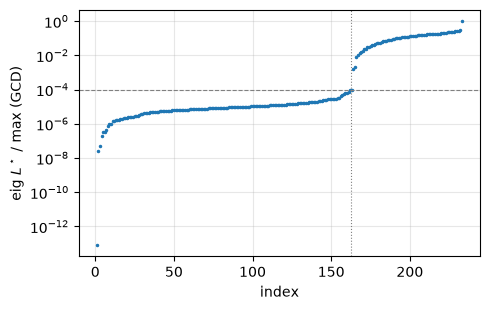

In [6]:
kerTol = 1e-4
lamGCD, UGCD = np.linalg.eigh(Msym(Qgcd._get_total_A(Qgcd.current_lags)))
N = UGCD[:, lamGCD < kerTol*lamGCD[-1]]
K = N.shape[1]
xs = Qgcd.current_xstar
xr = xs - N @ (N.conj().T @ xs)
print(f"eps {kerTol:.0e}: kernel dimension {K} of {Ndes}, largest kernel eigenvalue / max {lamGCD[K - 1]/lamGCD[-1]:.1e}, "
      f"next {lamGCD[K]/lamGCD[-1]:.1e}")

def lagrangianRatio(x):
    # scattering Lagrangian D - (x - x*)^H L* (x - x*), relative to D
    e = x - xs
    return 1 - np.real(e.conj() @ Msym(Qgcd._get_total_A(Qgcd.current_lags)) @ e)/Qgcd.current_dual

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.semilogy(np.arange(1, Ndes + 1), lamGCD/lamGCD[-1], '.', ms=3)
ax.axhline(kerTol, ls='--', c='gray', lw=0.8); ax.axvline(K + 0.5, ls=':', c='gray', lw=0.8)
ax.set_xlabel('index'); ax.set_ylabel(r'eig $L^\star$ / max (GCD)'); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## Kernel QCQP helpers

In [7]:
def qcqpParts(Q):
    # objective (A0, s0, c0) and constraints [(A_k, F_k, c_k)], f(x) = -x^H A x + 2 Re(x^H s) + c
    ck = np.r_[np.zeros(Q.n_proj_constr), Q.c_2j]
    cons = [(Msym(np.asarray(Ak)), Q.Fs[:, k].copy(), ck[k]) for k, Ak in enumerate(Q.precomputed_As)]
    return (Msym(np.asarray(Q.A0)), Q.s0.copy(), float(Q.c0)), cons

def shiftForm(A, s, c, x0, N):
    # f(x0 + N y) in the same form, in y
    Ax0 = A @ x0
    return Msym(N.conj().T @ A @ N), N.conj().T @ (s - Ax0), float(np.real(-x0.conj() @ Ax0 + 2*x0.conj() @ s) + c)

def generalQCQP(objective, cons):
    # QCQP with only general constraints (A2 = 1), objective (A0, s0, c0) and constraints [(B_j, s_2j, c_2j)]
    A0r, s0r, c0r = objective
    K = len(s0r)
    return DenseSharedProjQCQP(A0r, s0r, c0r, np.eye(K, dtype=complex), np.zeros(K, dtype=complex), [], Pstruct=sp.eye(K),
                               B_j=[c[0] for c in cons], s_2j=[c[1] for c in cons], c_2j=np.array([c[2] for c in cons]), verbose=0)

def consVec(con):
    # real coordinates of the constraint function -y^H B y + 2 Re(y^H s) + c
    B, s, c = con
    return np.r_[B.real.ravel(), B.imag.ravel(), s.real, s.imag, c]

def setLags(Q, lags):
    Q.current_lags = lags
    Q.current_dual = Q.get_dual(lags)[0]
    Q.current_xstar = Q._get_xstar(lags)[0]

class EvalCap(Exception):
    pass

def solveReduced(Qr, lags, maxEval=3000):
    # start from (1 + t) lags, the smallest |t| in the list that is strictly dual feasible (t < 0 shrinks toward lambda = 0, feasible for A0 > 0). The optimizer has no iteration limit and a
    # reduced dual can be unbounded below (infeasible restricted primal, see Kernel GCD), so get_dual is capped at maxEval calls and
    # the multipliers with the lowest unpenalized dual seen are kept. Returns t and whether the cap was hit.
    t = next(t for t in [1e-6, -1e-6, 1e-4, -1e-4, 1e-2, -1e-2, 0.1, -0.1, 1.0, -0.5, 10.0, -1.0] if Qr.is_dual_feasible((1 + t)*lags))
    l0 = (1 + t)*lags
    best = [Qr.get_dual(l0)[0], l0.copy()]
    count = [0]
    getDual = Qr.get_dual
    def cappedDual(l, *args, **kwargs):
        count[0] += 1
        if count[0] > maxEval:
            raise EvalCap
        out = getDual(l, *args, **kwargs)
        D = out[0] if not kwargs.get("penalty_vectors") else getDual(l)[0]
        if D < best[0]:
            best[0], best[1] = D, np.array(l, dtype=float).copy()
        return out
    Qr.get_dual = cappedDual
    capped = False
    try:
        Qr.solve_current_dual_problem(method='newton', init_lags=l0, opt_params=opt_params)
    except EvalCap:
        capped = True
    finally:
        del Qr.get_dual
    if capped or Qr.current_dual > best[0]:
        setLags(Qr, best[1])
    return t, capped

def projectorForm(p, a, B):
    # diagonal projector constraint Re(-x^H A1 P A2 x + 2 x^H A2^H P^H s1) at x = a + B y, as a general constraint in y
    return shiftForm(Msym(A1 @ (p[:, None]*A2)), A2.conj().T @ (np.conj(p)*s1), 0.0, a, B)

def addConstraint(cons, lags, new, tol=1e-8):
    # new constraint orthogonal to the span of cons, normalized, multiplier 0; dropped if it lies in the span
    M = np.array([consVec(cn) for cn in cons]).T
    v = consVec(new)
    g = np.linalg.lstsq(M, v, rcond=None)[0]
    B, s, c = new
    for gk, (Bk, sk, ck) in zip(g, cons):
        B, s, c = B - gk*Bk, s - gk*sk, c - gk*ck
    nrm = np.linalg.norm(consVec((B, s, c)))
    if nrm < tol*np.linalg.norm(v):
        return cons, lags, False
    return cons + [(B/nrm, s/nrm, c/nrm)], np.r_[lags, 0.0], True

def mergeLead(cons, lags, m):
    # the first m constraints merged by their multipliers into one (normalized), the dual is unchanged
    merged = [sum(l*cn[i] for l, cn in zip(lags[:m], cons[:m])) for i in range(3)]
    nrm = np.linalg.norm(consVec(merged))
    return [tuple(t/nrm for t in merged)] + cons[m:], np.r_[nrm, lags[m:]]

In [8]:
rot = np.exp(-1j*np.pi/4)
pReact = 1j/rot # p = j e^{j pi/4}: Re(conj(p) w) = Im(e^{-j pi/4} w), the component off the passive ray

def powerTerms(x):
    I = VtoI(x)
    r = Vinc - Ztot @ I
    return I, r, np.conj(I)*r

def complexDensity(I):
    u = Vinc - Ztot @ I + Zs*Ldiag*I
    return Zs*Ldiag*I/u

# check: the library projector constraint is Re(sum conj(p_i) w_i), and the reactive family gives q = Im(e^{-j pi/4} w)
rng = np.random.default_rng(1)
pt = rng.standard_normal(Ndes) + 1j*rng.standard_normal(Ndes)
w0 = powerTerms(xs)[2]
lib = constraintRes(DenseSharedProjQCQP(Obj, obj, obj0, A1, s1, [sp.diags(pt)], A2=A2), xs)[0]
print(f"projector constraint vs Re(sum conj(p) w): relative error {abs(lib - np.real(np.conj(pt) @ w0))/abs(lib):.1e}")
e0 = np.zeros(Ndes); e0[7] = 1
lib = constraintRes(DenseSharedProjQCQP(Obj, obj, obj0, A1, s1, [sp.diags(pReact*e0)], A2=A2), xs)[0]
print(f"reactive projector on basis function 7 vs Im(e^(-j pi/4) w_7): relative error {abs(lib - (rot*w0[7]).imag)/abs(lib):.1e}")

objective = (np.eye(K, dtype=complex), -N.conj().T @ Vinc, -np.linalg.norm(Vinc + xr)**2) # level 2: -||V + x_r + N y||^2 (N^H N = 1, N^H x_r = 0)
consGlob = [projectorForm(p, xr, N) for p in [np.ones(Ndes, dtype=complex), 1j*np.ones(Ndes, dtype=complex)]]

def fieldOf(x):
    return np.linalg.norm(Vinc + x)**2

t1 = time.time()
Qk = generalQCQP(objective, consGlob)
solveReduced(Qk, np.zeros(2))
print(f"level 2 global solve: {time.time() - t1:.1f}s")

projector constraint vs Re(sum conj(p) w): relative error 1.8e-15
reactive projector on basis function 7 vs Im(e^(-j pi/4) w_7): relative error 5.0e-14


level 2 global solve: 0.2s


In [9]:
def reduceQCQP(Q, x0, N):
    # QCQP of Q restricted to x = x0 + N y, all constraints general
    (A0, s0, c0), cons = qcqpParts(Q)
    return generalQCQP(shiftForm(A0, s0, c0, x0, N), [shiftForm(A, s, c, x0, N) for A, s, c in cons])

def kernelGCD(Qr, a, B, nIter=20, maxCon=None):
    # GCD inside the kernel x = a + B y of a reduced QCQP with general constraints only
    objective, cons = qcqpParts(Qr)
    maxCon = maxCon or len(cons) + 2*nIter
    hist, added, capped = [Qr.current_dual], 0, 0
    for it in range(nIter):
        lags = Qr.current_lags.copy()
        x = a + B @ Qr.current_xstar
        pV = (2*s1 - A1.conj().T @ x) * np.conj(A2 @ x) # max-violation projector
        u = np.linalg.eigh(Msym(Qr._get_total_A(lags)))[1][:, 0]
        v = B @ u
        pE = (A1.conj().T @ v) * np.conj(A2 @ v) # min-eigenvalue projector, unit modulus
        pE = np.divide(pE, np.abs(pE), out=np.zeros_like(pE), where=np.abs(pE) > 0)
        n0 = len(cons)
        for p in [pV, pE]:
            cons, lags, ok = addConstraint(cons, lags, projectorForm(p, a, B))
        if len(cons) == n0: # both projectors already in the span
            break
        added += len(cons) - n0
        if len(cons) > maxCon:
            cons, lags = mergeLead(cons, lags, len(cons) - maxCon + 1)
        Qr = generalQCQP(objective, cons)
        capped += solveReduced(Qr, lags)[1]
        hist.append(Qr.current_dual)
    return Qr, dict(hist=np.array(hist), added=added, capped=capped)

## Level 2: minimal total field in the kernel of the scattering dual, with GCD

The kernel QCQP above (global constraints only) is refined by GCD inside the kernel, using `kernelGCD` from `nullSpaceQCQP.ipynb`:
- **Projectors.** Each iteration evaluates the library's two projectors at the full-space current $x = a + B z^\star$ ($a = x_r$, $B = N$). The max-violation
  projector $p = (2 s_1 - A_1^H x) \odot \overline{A_2 x} = w$ has constraint value $\operatorname{Re}\sum_i \overline{p_i} w_i = \sum_i |w_i|^2$, i.e. the full complex local
  power, real and reactive part. The second is the min-eigenvalue projector.
- **Adding them.** Both are mapped to $z$ (`projectorForm`), orthogonalized against the span of the current constraint functions, added with
  multiplier 0, and the dual is re-solved (`solveReduced`, capped at 3000 dual evaluations).

The objective is $\sum_i |V_i + x_i|^2$ (positive definite, $\lambda = 0$ dual feasible). The dual is a lower bound on the minimal field of the currents with
the image part $x_r$ fixed.

In [10]:
def levelReport(name, Q, a, Bl, quantity, t=None):
    # the dual current of a level in the full space: bound vs attained objective, spectrum, scattering cost, binarity
    z = Q.current_xstar
    x = a + Bl @ z
    I, r, w = powerTerms(x)
    d = complexDensity(I)
    lam = lagSpectrum(Q)
    A0, s0, c0 = qcqpParts(Q)[0]
    attained = np.real(z.conj() @ A0 @ z - 2*z.conj() @ s0) - c0 # the minimized quantity at z*
    out = dict(x=x, Q=Q, a=a, B=Bl, attained=attained, bound=-Q.current_dual, dim=Bl.shape[1], ncon=Q.n_gen_constr,
               lamRatio=lam[0]/lam[-1], nker=int(np.count_nonzero(lam < 1e-8*lam[-1])),
               P=evalObj(I)/Qgcd.current_dual, Lag=lagrangianRatio(x), cGlob=np.linalg.norm(constraintRes(Qglob, x))/Qgcd.current_dual,
               wSum=np.sum(np.abs(w))/np.abs(I.conj() @ Vinc), reactive=np.sum(np.abs((rot*w).imag))/np.sum(np.abs(w)),
               metal=int(np.count_nonzero(np.abs(d - 1) < 0.05)), void=int(np.count_nonzero(np.abs(I) < 1e-2*np.abs(I).max())),
               field=np.sqrt(fieldOf(x)/fieldOf(xs)), current=np.linalg.norm(I)/np.linalg.norm(VtoI(xs)))
    print(f"{name}{'' if t is None else f' ({t:.0f}s)'}: dim {out['dim']}, {out['ncon']} constraints, "
          f"{quantity}: bound {out['bound']:.4e}, attained {out['attained']:.4e} (bound/attained {out['bound']/out['attained']:.4f}), "
          f"min/max eig {out['lamRatio']:.1e}, near-kernel (1e-8) {out['nker']}\n"
          f"    P/D {out['P']:.4f}, Lagrangian/D {out['Lag']:.4f}, ||c_global||/D {out['cGlob']:.1e}, sum|w|/|I^H V| {out['wSum']:.2e}, "
          f"reactive fraction {out['reactive']:.2f}, metal {out['metal']}, void {out['void']}, "
          f"|V + x| / |V + x*| {out['field']:.3f}, |I| / |I*| {out['current']:.3f}")
    return out

NgcdLevel = 20 # GCD iterations per level
levels = {}
levels["level 2, global"] = levelReport("level 2, global constraints", Qk, xr, N, "field |V + x|^2")
t1 = time.time()
Q2, info2 = kernelGCD(copy.deepcopy(Qk), xr, N, NgcdLevel)
levels["level 2"] = levelReport("level 2, GCD", Q2, xr, N, "field |V + x|^2", time.time() - t1)
levels["level 2"]["info"] = info2
print(f"    +{info2['added']} constraints, capped solves {info2['capped']}, "
      f"bound monotone over GCD: {bool(np.all(np.diff(-info2['hist']) >= -1e-9*np.abs(info2['hist'][:-1])))}")

level 2, global constraints: dim 162, 2 constraints, field |V + x|^2: bound 2.4706e+01, attained 2.4706e+01 (bound/attained 1.0000), min/max eig 1.8e-05, near-kernel (1e-8) 0
    P/D 0.9984, Lagrangian/D 0.9691, ||c_global||/D 6.0e-04, sum|w|/|I^H V| 9.65e+02, reactive fraction 0.86, metal 0, void 0, |V + x| / |V + x*| 0.741, |I| / |I*| 0.996


level 2, GCD (22s): dim 162, 42 constraints, field |V + x|^2: bound 7.5053e+01, attained 2.9233e+01 (bound/attained 2.5674), min/max eig 5.5e-12, near-kernel (1e-8) 1
    P/D 0.9961, Lagrangian/D 0.9964, ||c_global||/D 3.2e+02, sum|w|/|I^H V| 6.86e+02, reactive fraction 0.64, metal 0, void 3, |V + x| / |V + x*| 0.806, |I| / |I*| 0.992
    +40 constraints, capped solves 0, bound monotone over GCD: True


## Level 3: minimal current in the kernel of level 2, fresh global bound and GCD

The level-2 Lagrangian $A_0 + \sum_k \lambda_k B_k$ is split into image and near-kernel $N_2$ at eigenvalues below $10^{-3}$ of the largest. That is
wider than its hard-case direction, so level 3 has more room. The level-2
Lagrangian is then no longer constant on $N_2$, and its value at the level-3 current is reported. The image part $z_r$ of the level-2 dual current is fixed: $x = a_3 + B_3 u$ with $a_3 = x_r + N z_r$ and $B_3 = N N_2$.

Level 3 minimizes the current, $\sum_i |I_i|^2 = \|W x\|^2$, which is positive definite. It starts from a fresh global bound: only the power constraints
$p = \mathbf 1, j\mathbf 1$ at $x = a_3 + B_3 u$ (`projectorForm`), solved from $\lambda = 0$. GCD then adds the local power projectors in the level-3 kernel.

With $\dim N_2 = K_2$, the constraint functions of $u$ span $(K_2 + 1)^2$ real dimensions. Starting from 2 constraints, GCD can add up to $(K_2 + 1)^2 - 2$.

In [11]:
kerTol2 = 1e-3 # level-2 split: eig < kerTol2 * max eig (wider than the hard-case direction, so level 3 has room)
lam2, U2 = np.linalg.eigh(Msym(Q2._get_total_A(Q2.current_lags)))
N2 = U2[:, lam2 < kerTol2*lam2[-1]]
print(f"level-2 Lagrangian: dim {len(lam2)}, near-kernel ({kerTol2:.0e}) {N2.shape[1]}, smallest eigenvalues / max: "
      + ", ".join(f"{v:.1e}" for v in lam2[:6]/lam2[-1]))
if N2.shape[1] == 0:
    print("no near-kernel: the level-2 dual current is unique, level 3 is skipped")
else:
    z2 = Q2.current_xstar
    zr = z2 - N2 @ (N2.conj().T @ z2)
    a3, B3 = xr + N @ zr, N @ N2
    objective3 = shiftForm(WH @ W, np.zeros(Ndes, dtype=complex), 0.0, a3, B3) # -|W x|^2 in u
    cons3 = [projectorForm(p, a3, B3) for p in [np.ones(Ndes, dtype=complex), 1j*np.ones(Ndes, dtype=complex)]] # fresh global bound
    t1 = time.time()
    Q3 = generalQCQP(objective3, cons3)
    capped3 = solveReduced(Q3, np.zeros(2))[1]
    # the level-2 Lagrangian is not constant on the wider kernel: its value at the level-3 current, relative to the level-2 dual
    def level2Lagrangian(u):
        e = zr + N2 @ u - z2
        return 1 - np.real(e.conj() @ Msym(Q2._get_total_A(Q2.current_lags)) @ e)/Q2.current_dual
    levels["level 3, global"] = levelReport("level 3, global constraints", Q3, a3, B3, "current |I|^2", time.time() - t1)
    # check: the two constraints are the global power balance at x = a3 + B3 u; they must equal the full-space residuals
    x3 = a3 + B3 @ Q3.current_xstar
    print(f"    shiftForm check: global residuals reduced {constraintRes(Q3, Q3.current_xstar)[:2]}, full space {constraintRes(Qglob, x3)}")
    t1 = time.time()
    Q3g, info3 = kernelGCD(copy.deepcopy(Q3), a3, B3, NgcdLevel)
    levels["level 3"] = levelReport("level 3, GCD", Q3g, a3, B3, "current |I|^2", time.time() - t1)
    levels["level 3"]["info"] = info3
    print(f"    +{info3['added']} constraints, capped solves {int(capped3) + info3['capped']}, "
          f"level-2 Lagrangian at the level-3 current / level-2 dual {level2Lagrangian(Q3g.current_xstar):.4f}")

level-2 Lagrangian: dim 162, near-kernel (1e-03) 2, smallest eigenvalues / max: 5.5e-12, 4.7e-05, 1.0e-03, 2.7e-03, 4.0e-03, 5.7e-03
level 3, global constraints (0s): dim 2, 2 constraints, current |I|^2: bound 8.1697e+07, attained 8.1697e+07 (bound/attained 1.0000), min/max eig 5.9e-01, near-kernel (1e-8) 0
    P/D 0.9965, Lagrangian/D 0.9944, ||c_global||/D 1.2e-04, sum|w|/|I^H V| 1.09e+03, reactive fraction 0.69, metal 0, void 2, |V + x| / |V + x*| 1.299, |I| / |I*| 1.006
    shiftForm check: global residuals reduced [-7.99059067e-08  2.12136738e-03], full space [-7.9905945e-08  2.1213674e-03]


level 3, GCD (1s): dim 2, 6 constraints, current |I|^2: bound 2.7246e+12, attained 8.2605e+07 (bound/attained 32983.0837), min/max eig 2.9e-01, near-kernel (1e-8) 0
    P/D 0.9958, Lagrangian/D 0.9933, ||c_global||/D 6.6e-01, sum|w|/|I^H V| 1.07e+03, reactive fraction 0.73, metal 0, void 2, |V + x| / |V + x*| 1.324, |I| / |I*| 1.012
    +4 constraints, capped solves 1, level-2 Lagrangian at the level-3 current / level-2 dual 1.0001


/Users/xjliska/GIT/dolphindes/.venv/lib/python3.12/site-packages/scipy/sparse/linalg/_eigen/arpack/arpack.py:1664: RuntimeWarning: k >= N - 1 for N * N square matrix. Attempting to use scipy.linalg.eig instead.
  ret = eigs(A, k, M=M, sigma=sigma, which=which, v0=v0,


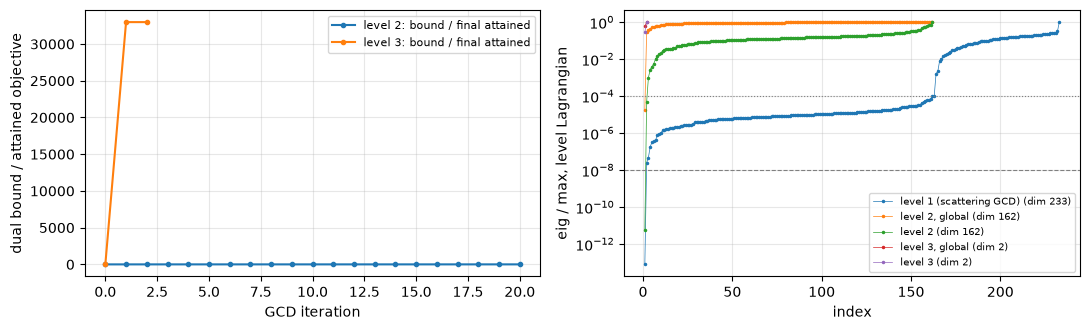

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for name in ["level 2", "level 3"]:
    if name in levels and "info" in levels[name]:
        axes[0].plot(-levels[name]["info"]["hist"]/levels[name]["attained"], 'o-', ms=3, label=f"{name}: bound / final attained")
axes[0].set_xlabel('GCD iteration'); axes[0].set_ylabel('dual bound / attained objective'); axes[0].legend(fontsize=8)
for name, r in [("level 1 (scattering GCD)", dict(Q=Qgcd))] + list(levels.items()):
    lam = lagSpectrum(r["Q"])
    axes[1].semilogy(np.arange(1, len(lam) + 1), lam/lam[-1], '.-', ms=3, lw=0.5, label=f"{name} (dim {len(lam)})")
axes[1].axhline(1e-8, ls='--', c='gray', lw=0.8); axes[1].axhline(1e-4, ls=':', c='gray', lw=0.8)
axes[1].set_xlabel('index'); axes[1].set_ylabel('eig / max, level Lagrangian'); axes[1].legend(fontsize=7)
for ax in axes:
    ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

kernelRes = {n: levels[n] for n in ["level 2", "level 3"] if n in levels}

## Combined QCQP: the kernel objectives as equality constraints in the full space

The cascade fixes the image parts level by level. Here, instead, the values the kernel levels reached are imposed as two general equality
constraints on the full scattering problem:
$$\max_x\; \tfrac12 I^H R_0 I \quad \text{s.t.} \quad \operatorname{Re}\Big(\sum_i \overline{p_i}\, w_i\Big) = 0 \ (\text{global, then GCD}), \qquad \|V + x\|^2 = F_2, \qquad \|I\|^2 = I_3 .$$
Here $F_2$ is the field reached at level 2 and $I_3$ the current norm reached at level 3.
- **Combined Lagrange matrix.** The Lagrangian is $L_1(\lambda) + \mu_2\, 1 + \mu_3\, W^H W$. The weights $\mu_2, \mu_3$ of the kernel objectives are the multipliers of the two
  general constraints, determined by the dual solver together with the projector multipliers.
- **Library form.** With $A_2 = W$ (so $A_2 x = -I$), the general constraints $\operatorname{Re}(-x^H A_2^H B A_2 x + 2 x^H A_2^H s_2 + c_2) = 0$ are
  - $B = Z_0^H Z_0$, $s_2 = -Z_0^H V$, $c_2 = F_2 - \|V\|^2$ for $F_2 - \|V + x\|^2 = 0$;
  - $B = 1$, $s_2 = 0$, $c_2 = I_3$ for $I_3 - \|I\|^2 = 0$.
- **Two sets of values.**
  - from the global kernel solves (level 2 and level 3 with the power constraints only), which are attained by currents that satisfy the
    power balance;
  - from the kernel GCD levels, whose dual currents violate it.
- **Procedure.** Each is solved by the global bound and `run_gcd` (the general constraints are kept through GCD) for three GCD realizations.

In [13]:
def kernelEqualities(F2, I3):
    # general constraints F2 - |V + x|^2 = 0 and I3 - |I|^2 = 0 in the library form with A2 = W
    return dict(B_j=[Z0.conj().T @ Z0, np.eye(Ndes, dtype=complex)],
                s_2j=[-Z0.conj().T @ Vinc, np.zeros(Ndes, dtype=complex)],
                c_2j=np.array([F2 - np.linalg.norm(Vinc)**2, I3]))

# check: the general constraint residuals at a test point are F2 - |V + x|^2 and I3 - |I|^2
Qt = DenseSharedProjQCQP(Obj, obj, obj0, A1, s1, PlistGlob, A2=A2, verbose=0, **kernelEqualities(1.0, 2.0))
rt = constraintRes(Qt, xs)[2:]
print(f"general constraint check: relative errors {abs(rt[0] - (1.0 - fieldOf(xs)))/fieldOf(xs):.1e}, "
      f"{abs(rt[1] - (2.0 - np.linalg.norm(VtoI(xs))**2))/np.linalg.norm(VtoI(xs))**2:.1e}")

def solveCombined(F2, I3, seed):
    np.random.seed(seed)
    Q = DenseSharedProjQCQP(Obj, obj, obj0, A1, s1, PlistGlob, A2=A2, verbose=0, **kernelEqualities(F2, I3))
    Q.solve_current_dual_problem(method='newton', init_lags=np.array([1.0, 0.0, 0.0, 0.0]), opt_params=opt_params)
    Dglob, lagsGlob = Q.current_dual, Q.current_lags.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        Q.run_gcd(gcd_params)
    return Q, Dglob, lagsGlob

def combinedReport(name, Q, Dglob, lagsGlob, F2, I3):
    x = Q.current_xstar
    I = VtoI(x)
    lam = lagSpectrum(Q)
    mu = Q.current_lags[Q.n_proj_constr:]
    out = dict(x=x, Q=Q, D=Q.current_dual, Dglob=Dglob, P=evalObj(I), mu=mu, muGlob=lagsGlob[-2:], lamRatio=lam[0]/lam[-1],
               resF=(fieldOf(x) - F2)/F2, resI=(np.linalg.norm(I)**2 - I3)/I3,
               cGlob=np.linalg.norm(constraintRes(Qglob, x))/Qgcd.current_dual,
               wSum=np.sum(np.abs(localViolation(I)))/np.abs(I.conj() @ Vinc))
    print(f"{name}: D {out['D']:.6f} W (global {Dglob:.6f}, scattering GCD {Qgcd.current_dual:.6f}), P(x*) {out['P']:.4f} W, "
          f"mu_field {mu[0]:+.3e} (global {lagsGlob[-2]:+.3e}), mu_current {mu[1]:+.3e} (global {lagsGlob[-1]:+.3e}), "
          f"min/max eig {out['lamRatio']:.1e}, field residual {out['resF']:+.1e}, current residual {out['resI']:+.1e}, "
          f"||c_global||/D {out['cGlob']:.1e}, sum|w|/|I^H V| {out['wSum']:.2e}", flush=True)
    return out

targets = {"global kernel values": (levels["level 2, global"]["attained"], levels["level 3, global"]["attained"]),
           "GCD kernel values": (levels["level 2"]["attained"], levels["level 3"]["attained"])}
combined = {}
for name, (F2, I3) in targets.items():
    print(f"== {name}: F2 = {F2:.4e} (|V + x*|^2 = {fieldOf(xs):.4e}), I3 = {I3:.4e} (|I*|^2 = {np.linalg.norm(VtoI(xs))**2:.4e})")
    combined[name] = []
    for seed in [0, 1, 2]:
        combined[name].append(combinedReport(f"  seed {seed}", *solveCombined(F2, I3, seed), F2, I3))
    xsr = [r["x"] for r in combined[name]]
    Ds = np.array([r["D"] for r in combined[name]])
    print(f"  spread over the realizations: bound {(Ds.max() - Ds.min())/abs(Ds.mean()):.1e}, dual current "
          f"{max(np.linalg.norm(a - b)/np.linalg.norm(b) for i, a in enumerate(xsr) for b in xsr[i + 1:]):.2e}")

general constraint check: relative errors 9.8e-14, 2.1e-14
== global kernel values: F2 = 2.4706e+01 (|V + x*|^2 = 4.4959e+01), I3 = 8.1697e+07 (|I*|^2 = 8.0723e+07)


  seed 0: D 16.678612 W (global 18.369947, scattering GCD 17.737062), P(x*) 16.7026 W, mu_field +8.086e-02 (global +2.684e-02), mu_current -2.793e-08 (global -7.343e-09), min/max eig 2.5e-14, field residual -7.2e-01, current residual -1.4e-02, ||c_global||/D 3.7e+02, sum|w|/|I^H V| 2.43e+02


  seed 1: D 16.705307 W (global 18.369947, scattering GCD 17.737062), P(x*) 16.6500 W, mu_field +8.135e-02 (global +2.684e-02), mu_current -2.807e-08 (global -7.343e-09), min/max eig 2.9e-13, field residual -7.9e-01, current residual -5.9e-02, ||c_global||/D 3.8e+02, sum|w|/|I^H V| 2.22e+02


  seed 2: D 16.700160 W (global 18.369947, scattering GCD 17.737062), P(x*) 16.3584 W, mu_field +8.064e-02 (global +2.684e-02), mu_current -2.788e-08 (global -7.343e-09), min/max eig 2.1e-14, field residual -1.1e-01, current residual -2.0e-01, ||c_global||/D 7.9e+01, sum|w|/|I^H V| 6.59e+02


  spread over the realizations: bound 1.6e-03, dual current 1.21e+00
== GCD kernel values: F2 = 2.9233e+01 (|V + x*|^2 = 4.4959e+01), I3 = 8.2605e+07 (|I*|^2 = 8.0723e+07)


  seed 0: D 17.002097 W (global 18.436058, scattering GCD 17.737062), P(x*) 16.8884 W, mu_field +4.727e-02 (global +9.118e-03), mu_current -1.984e-08 (global -2.522e-09), min/max eig 1.6e-13, field residual -7.7e-01, current residual -8.9e-02, ||c_global||/D 3.9e+02, sum|w|/|I^H V| 2.93e+02


  seed 1: D 17.005498 W (global 18.436058, scattering GCD 17.737062), P(x*) 16.6284 W, mu_field +4.854e-02 (global +9.118e-03), mu_current -2.036e-08 (global -2.522e-09), min/max eig 8.7e-14, field residual +5.0e-01, current residual -1.9e-01, ||c_global||/D 4.6e+02, sum|w|/|I^H V| 8.68e+02


  seed 2: D 16.999151 W (global 18.436058, scattering GCD 17.737062), P(x*) 16.8982 W, mu_field +4.738e-02 (global +9.118e-03), mu_current -2.011e-08 (global -2.522e-09), min/max eig 1.6e-13, field residual -7.7e-01, current residual -7.7e-02, ||c_global||/D 4.1e+02, sum|w|/|I^H V| 2.99e+02


  spread over the realizations: bound 3.7e-04, dual current 2.36e+00


## Pointwise inference and the complex material density

As in `nullSpaceMinField.ipynb`. The complex density $d_i = Z_s L_{ii} I_i / u_i$, with $u = V - Z_\mathrm{tot} I + Z_s L_{ii} I$, is 1 on metal and 0 where the
basis function is removed. The pointwise fits project it:
- the admittance form takes $\operatorname{clip}(\operatorname{Re} d, 0, 1)$;
- the impedance form projects the series impedance onto the passive ray.

The binary design with the largest scattered power over the rounding thresholds is kept.

In [14]:
dMin = 1e-6 # basis functions with d_i < dMin are removed in the realized structure
thsLog = np.logspace(-6, 0, 61)[:-1] # thresholds for binary rounding of d

def inferDimp(I):
    # impedance form: series impedance projected onto the passive ray, d = 1/(1 + t)
    nz = I != 0
    r = np.zeros(Ndes, dtype=complex)
    r[nz] = (Vinc - Ztot @ I)[nz]/I[nz]
    t = np.maximum(0, np.real(np.conj(Zs)*r)/(np.abs(Zs)**2*Ldiag))
    return np.where(nz, 1/(1 + t), 0.0)

def inferDadm(I):
    # admittance form: real part of the complex density, clipped
    return np.clip(complexDensity(I).real, 0, 1)

def realizedCurrent(d):
    # (Ztot + diag(Zs Lii (1/d - 1))) I = V on the kept basis functions, I = 0 elsewhere
    keep = d >= dMin
    I = np.zeros(Ndes, dtype=complex)
    Zd = Ztot + np.diag(Zs*Ldiag*(1/np.maximum(d, dMin) - 1))
    I[keep] = np.linalg.solve(Zd[np.ix_(keep, keep)], Vinc[keep])
    return I

def bestBinary(d):
    designs = [d > t for t in thsLog]
    Is = [realizedCurrent(k.astype(float)) for k in designs]
    Pb = np.array([evalObj(I) for I in Is])
    k = int(np.argmax(Pb))
    return dict(keep=designs[k], I=Is[k], P=Pb[k], th=thsLog[k])

print(f"full plate: max |d - 1| = {np.abs(complexDensity(Ifull) - 1).max():.1e}")
final = {"GCD x* (reference)": xs, **{n: r["x"] for n, r in kernelRes.items()}, **{f"combined, {n}": rs[0]["x"] for n, rs in combined.items()}}
inference = {}
for name, x in final.items():
    I = VtoI(x)
    d = complexDensity(I)
    inference[name] = dict(d=d, **{form: bestBinary(infer(I)) for form, infer in [("impedance form", inferDimp), ("admittance form", inferDadm)]})
    print(f"{name:20s}: |d| quantiles 50/90/max " + "/".join(f"{q:.1e}" for q in np.quantile(np.abs(d), [0.5, 0.9, 1.0]))
          + f", |d - 1| < 0.1: {np.count_nonzero(np.abs(d - 1) < 0.1):3d}, "
          + ", ".join(f"{form} P/D {inference[name][form]['P']/Qgcd.current_dual:.4f} ({inference[name][form]['P']:.3e} W, kept {inference[name][form]['keep'].sum()})"
                      for form in ["impedance form", "admittance form"]))

full plate: max |d - 1| = 1.2e-09
GCD x* (reference)  : |d| quantiles 50/90/max 1.3e-04/8.0e-04/3.5e-03, |d - 1| < 0.1:   0, impedance form P/D 0.0043 (7.650e-02 W, kept 177), admittance form P/D 0.0001 (1.923e-03 W, kept 101)
level 2             : |d| quantiles 50/90/max 1.4e-04/8.2e-04/7.0e-03, |d - 1| < 0.1:   0, impedance form P/D 0.2758 (4.891e+00 W, kept 147), admittance form P/D 0.0001 (2.374e-03 W, kept 84)
level 3             : |d| quantiles 50/90/max 1.2e-04/6.3e-04/6.3e-03, |d - 1| < 0.1:   0, impedance form P/D 0.0028 (4.882e-02 W, kept 153), admittance form P/D 0.0001 (1.600e-03 W, kept 85)
combined, global kernel values: |d| quantiles 50/90/max 1.8e-04/2.4e-03/8.7e-03, |d - 1| < 0.1:   0, impedance form P/D 0.0023 (4.121e-02 W, kept 230), admittance form P/D 0.0000 (3.220e-05 W, kept 58)
combined, GCD kernel values: |d| quantiles 50/90/max 1.9e-04/1.6e-03/4.9e-02, |d - 1| < 0.1:   0, impedance form P/D 0.0026 (4.650e-02 W, kept 197), admittance form P/D 0.0001 (1.241e-03 

### Relaxed designs (no rounding)

The structure with the relaxed density $d_i \in [0, 1]$ is solved directly in the admittance form, $(Z_\mathrm{tot} + \operatorname{diag}(Z_s L_{ii}(1/d_i - 1))) I = V$
(basis functions with $d_i < 10^{-6}$ removed). Two densities per current:
- $\operatorname{clip}(\operatorname{Re} d, 0, 1)$ of the complex density (admittance form);
- the passive projection of the series impedance (impedance form).

A density $0 < d < 1$ is a resistive sheet, so a relaxed design is not a copper structure. It shows what the inferred density achieves before
rounding.

In [15]:
def grayFraction(d):
    return np.mean((d > 0.05) & (d < 0.95))

relaxed = {}
for name, x in final.items():
    I = VtoI(x)
    dens = {"Re d clipped": inferDadm(I), "impedance form": inferDimp(I)}
    relaxed[name] = {k: dict(d=dk, P=evalObj(realizedCurrent(dk))) for k, dk in dens.items()}
    print(f"{name:42s}: dual current P/D {evalObj(I)/Qgcd.current_dual:.4f}; " + "; ".join(
        f"{k}: relaxed P/D {v['P']/Qgcd.current_dual:.4f} ({v['P']:.3e} W, gray {grayFraction(v['d']):.0%}), "
        f"binary {inference[name]['admittance form' if k == 'Re d clipped' else 'impedance form']['P']/Qgcd.current_dual:.4f}"
        for k, v in relaxed[name].items()))

GCD x* (reference)                        : dual current P/D 1.0000; Re d clipped: relaxed P/D 0.0001 (1.351e-03 W, gray 0%), binary 0.0001; impedance form: relaxed P/D 0.0026 (4.586e-02 W, gray 0%), binary 0.0043
level 2                                   : dual current P/D 0.9961; Re d clipped: relaxed P/D 0.0002 (2.681e-03 W, gray 0%), binary 0.0001; impedance form: relaxed P/D 0.0025 (4.441e-02 W, gray 0%), binary 0.2758
level 3                                   : dual current P/D 0.9958; Re d clipped: relaxed P/D 0.0001 (1.553e-03 W, gray 0%), binary 0.0001; impedance form: relaxed P/D 0.0025 (4.488e-02 W, gray 0%), binary 0.0028
combined, global kernel values            : dual current P/D 0.9417; Re d clipped: relaxed P/D 0.0000 (2.289e-05 W, gray 0%), binary 0.0000; impedance form: relaxed P/D 0.0024 (4.205e-02 W, gray 0%), binary 0.0023
combined, GCD kernel values               : dual current P/D 0.9522; Re d clipped: relaxed P/D 0.0001 (1.354e-03 W, gray 0%), binary 0.0001; imp

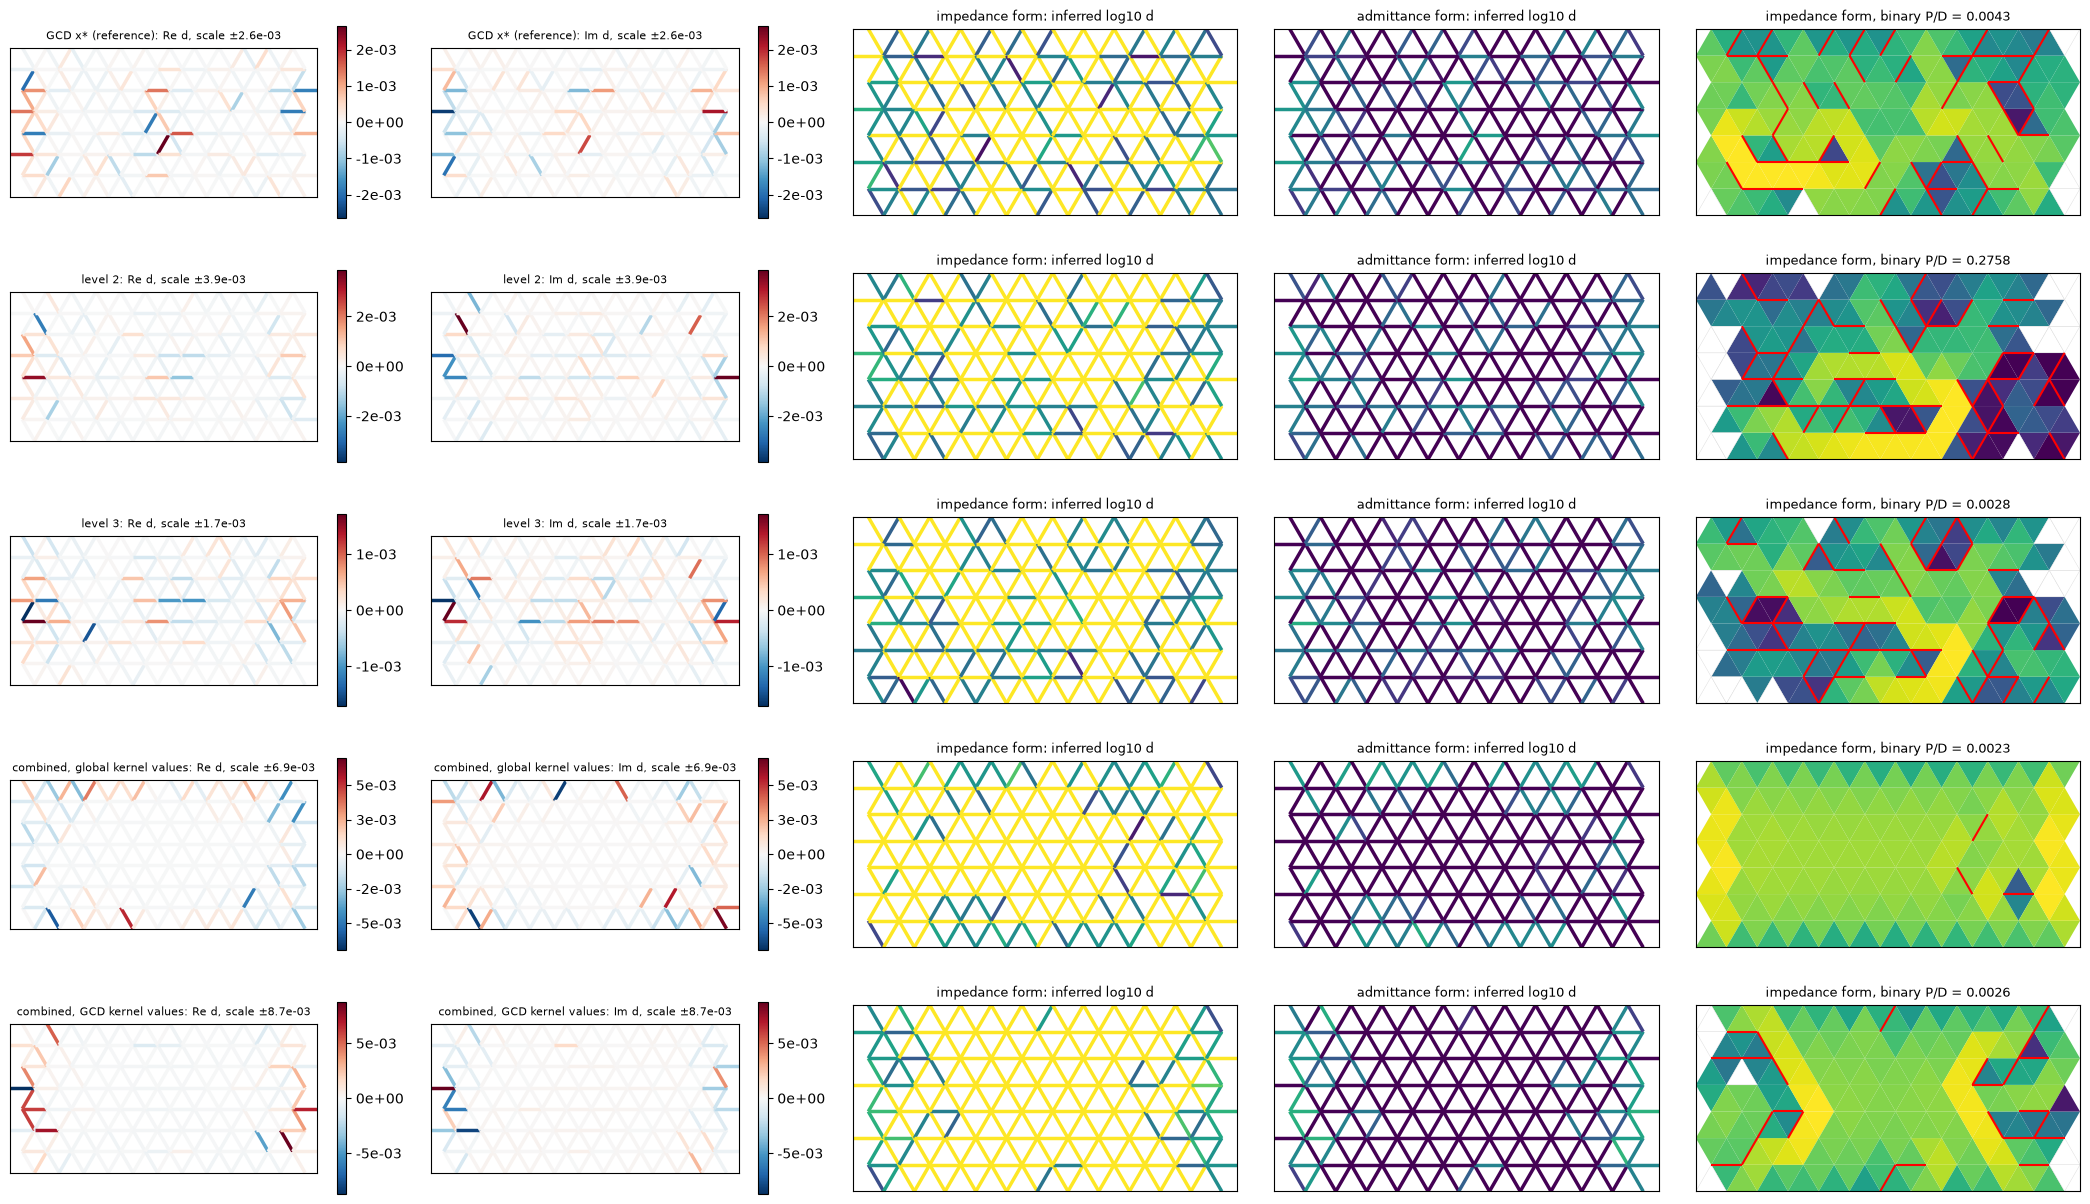

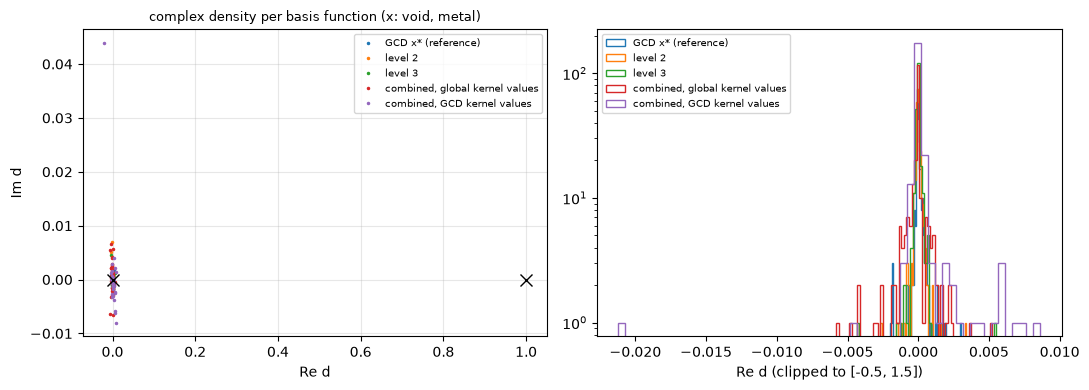

In [16]:
# final pointwise densities: real and imaginary part of the complex density, the inferred passive densities, and the binary design
names = list(inference)
fig, axes = plt.subplots(len(names), 5, figsize=(21, 2.5*len(names)))
for row, name in zip(axes, names):
    r = inference[name]
    plotComplexDensity(row[:2], r["d"], name)
    I = VtoI(final[name])
    for ax, form, infer in [(row[2], "impedance form", inferDimp), (row[3], "admittance form", inferDadm)]:
        lc = plotDensity(ax, infer(I), f"{form}: inferred log10 d")
    form = max(["impedance form", "admittance form"], key=lambda f: r[f]["P"])
    plotStructure(row[4], r[form]["keep"], r[form]["I"], f"{form}, binary P/D = {r[form]['P']/Qgcd.current_dual:.4f}")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in names:
    d = inference[name]["d"]
    axes[0].plot(d.real, d.imag, '.', ms=3, label=name)
    axes[1].hist(np.clip(d.real, -0.5, 1.5), bins=60, histtype='step', label=name)
axes[0].plot([0, 1], [0, 0], 'kx', ms=8); axes[0].set_xlabel('Re d'); axes[0].set_ylabel('Im d'); axes[0].legend(fontsize=7)
axes[0].set_title('complex density per basis function (x: void, metal)', fontsize=9); axes[0].grid(True, alpha=0.3)
axes[1].set_yscale('log'); axes[1].set_xlabel('Re d (clipped to [-0.5, 1.5])'); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## Conclusions

These are the numbers of one run; GCD is not exactly reproducible.

**Cascade (field, then current; fresh global bound then GCD at each level).**

| level | dim | bound / attained | min/max eig | power balance $\|c\|/D$ |
|---|---|---|---|---|
| 1, scattering GCD | 233 | (D = 17.74 W) | $8\times10^{-14}$ | $7\times10^{-3}$ |
| 2, field, global | 162 | 1.000 | $2\times10^{-5}$ | $6\times10^{-4}$ |
| 2, field, GCD | 162 | 2.57 | $6\times10^{-12}$ | 320 |
| 3, current, global | 2 | 1.000 | 0.59 | $1\times10^{-4}$ |
| 3, current, GCD | 2 | $3\times10^4$ (capped) | 0.29 | 0.66 |

The global steps are strongly dual and feasible. Each GCD drives its level into the hard case or makes the restricted problem infeasible.

**Combined QCQP (kernel objectives as equality constraints in the full space).**
- **Check.** The two general constraints reproduce $F_2 - \|V + x\|^2$ and $I_3 - \|I\|^2$ to $10^{-13}$.
- **The dual is reproducible.** Over three GCD realizations:
  - bound: 16.68–16.71 W with the global kernel values, 17.00–17.01 W with the GCD kernel values;
  - weights determined by the solver: $\mu_\mathrm{field} = +0.081$ and $+0.048$ (to 1 %), $\mu_\mathrm{current} = -2.8\times10^{-8}$ and $-2.0\times10^{-8}$.

  The positive field weight adds curvature; the small negative current weight removes some.
- **What the bound means.** It is lower than the scattering GCD bound, but it holds only for structures whose field and current equal $F_2$ and $I_3$,
  not for all structures.
- **The combined Lagrange matrix is not positive definite.** At the dual optimum, $L_1(\lambda) + \mu_2 + \mu_3 W^H W$ ends in the hard case again
  (min/max $2\times10^{-14}$ to $3\times10^{-13}$). The solver picks exactly the weights that keep it singular: a definite $L$ at the optimum would let the dual
  decrease further.
- **The dual current is not feasible, and not unique.** It misses the field equality by up to 79 %, the current equality by up to 20 %, and the
  power balance by about $400\,D$. It changes by 120–240 % between realizations.

**Why the solver cannot produce a definite matrix.** A definite Lagrangian at the dual optimum means the convex relaxation is tight, so that a
single current satisfies all constraints. With the local power constraints (GCD) and the extra equalities, no single current does. The relaxed
optimum is a mixture, and complementary slackness forces $L$ to vanish on its span. Adding the kernel objectives as constraints adds more
conditions and does not make the relaxation tighter. Uniqueness has to come from a strictly convex objective whose level is solved without
the local constraints, i.e. the global steps above. Those are definite and reproducible to 1–4 %.

**Inference.**
- **Relaxed designs.** All are the full plate (0.25 %), including the combined currents.
- **Binary designs.** They are 0.23–0.43 % of the bound, with one exception: the level-2 GCD current gives an impedance-form design at **27.6 % of the
  bound (4.89 W)**. That is the best design of all the nullspace notebooks, about $50\times$ the full plate. It is a single realization; earlier runs of the
  same level gave 0.26–0.43 %, so it reflects the GCD randomness rather than a reproducible property of the method. It is worth keeping and
  re-evaluating directly.